# UCS420 - Cognitive Computing
## Lab Assignment 8: NLP using Python-II
(Feature extraction from text, sentiment analysis and text generation)

**Name:** Kovid Kumar  
**Roll No:** 1024170353  
**Branch:** COPC, Thapar Institute of Engineering and Technology

In [1]:
# installing/importing the libraries and downloading nltk data
import re
import nltk
import string
import warnings
warnings.filterwarnings('ignore')

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

True

## Q1. Text preprocessing on my own paragraph

In [2]:
# my paragraph about cricket
text = """Cricket is more than just a game for me, it is a feeling that comes alive every time India plays a match. I still remember watching the 2011 World Cup final with my family and shouting at the television after every ball. Virat Kohli's chase against Pakistan in 2022 is one of the best innings I have ever seen. Playing gully cricket with friends on weekends is also my favourite way to relax after a tiring week. Every player on the field teaches us something about hard work, patience and never giving up. I hope to watch many more thrilling matches in the stadium one day."""

print(text)

Cricket is more than just a game for me, it is a feeling that comes alive every time India plays a match. I still remember watching the 2011 World Cup final with my family and shouting at the television after every ball. Virat Kohli's chase against Pakistan in 2022 is one of the best innings I have ever seen. Playing gully cricket with friends on weekends is also my favourite way to relax after a tiring week. Every player on the field teaches us something about hard work, patience and never giving up. I hope to watch many more thrilling matches in the stadium one day.


**1. Lowercase and remove punctuation using re**

In [3]:
lower_text = text.lower()
clean_text = re.sub(r'[^\w\s]', '', lower_text)
print(clean_text)

cricket is more than just a game for me it is a feeling that comes alive every time india plays a match i still remember watching the 2011 world cup final with my family and shouting at the television after every ball virat kohlis chase against pakistan in 2022 is one of the best innings i have ever seen playing gully cricket with friends on weekends is also my favourite way to relax after a tiring week every player on the field teaches us something about hard work patience and never giving up i hope to watch many more thrilling matches in the stadium one day


**2. Tokenize into words and sentences**

In [4]:
from nltk.tokenize import word_tokenize, sent_tokenize

# sentences are taken from the original text (before removing punctuation)
sentences = sent_tokenize(text)
print("Number of sentences:", len(sentences))
for i, s in enumerate(sentences, 1):
    print(i, s)

words = word_tokenize(clean_text)
print("\nNumber of words:", len(words))
print(words)

Number of sentences: 6
1 Cricket is more than just a game for me, it is a feeling that comes alive every time India plays a match.
2 I still remember watching the 2011 World Cup final with my family and shouting at the television after every ball.
3 Virat Kohli's chase against Pakistan in 2022 is one of the best innings I have ever seen.
4 Playing gully cricket with friends on weekends is also my favourite way to relax after a tiring week.
5 Every player on the field teaches us something about hard work, patience and never giving up.
6 I hope to watch many more thrilling matches in the stadium one day.

Number of words: 106
['cricket', 'is', 'more', 'than', 'just', 'a', 'game', 'for', 'me', 'it', 'is', 'a', 'feeling', 'that', 'comes', 'alive', 'every', 'time', 'india', 'plays', 'a', 'match', 'i', 'still', 'remember', 'watching', 'the', '2011', 'world', 'cup', 'final', 'with', 'my', 'family', 'and', 'shouting', 'at', 'the', 'television', 'after', 'every', 'ball', 'virat', 'kohlis', 'cha

**3. split() vs word_tokenize()**

In [5]:
# comparing on the original text so the difference in punctuation handling is visible
split_tokens = text.split()
nltk_tokens = word_tokenize(text)

print("split() tokens      :", len(split_tokens))
print("word_tokenize tokens:", len(nltk_tokens))
print()
print("First 20 with split()        :", split_tokens[:20])
print("First 20 with word_tokenize():", nltk_tokens[:20])

split() tokens      : 106
word_tokenize tokens: 115

First 20 with split()        : ['Cricket', 'is', 'more', 'than', 'just', 'a', 'game', 'for', 'me,', 'it', 'is', 'a', 'feeling', 'that', 'comes', 'alive', 'every', 'time', 'India', 'plays']
First 20 with word_tokenize(): ['Cricket', 'is', 'more', 'than', 'just', 'a', 'game', 'for', 'me', ',', 'it', 'is', 'a', 'feeling', 'that', 'comes', 'alive', 'every', 'time', 'India']


In [6]:
# tokens that are different in both
print("Only in split():", [t for t in split_tokens if t not in nltk_tokens][:15])
print("Only in word_tokenize():", [t for t in nltk_tokens if t not in split_tokens][:15])

Only in split(): ['me,', 'match.', 'ball.', "Kohli's", 'seen.', 'week.', 'work,', 'up.', 'day.']
Only in word_tokenize(): ['me', ',', 'match', '.', 'ball', '.', 'Kohli', "'s", 'seen', '.', 'week', '.', 'work', ',', 'up']


**Difference:** `split()` only cuts the string wherever there is whitespace, so punctuation stays stuck to the words (for example `me,` or `match.` or `Kohli's`). `word_tokenize()` is smarter, it separates punctuation marks into their own tokens (`,` and `.`) and also breaks words like `Kohli's` into `Kohli` and `'s`. Because of this word_tokenize gives more tokens and they are more useful for further processing.

**4. Remove stopwords**

In [7]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]

print("Words before:", len(words))
print("Words after :", len(filtered_words))
print(filtered_words)

Words before: 106
Words after : 62
['cricket', 'game', 'feeling', 'comes', 'alive', 'every', 'time', 'india', 'plays', 'match', 'still', 'remember', 'watching', '2011', 'world', 'cup', 'final', 'family', 'shouting', 'television', 'every', 'ball', 'virat', 'kohlis', 'chase', 'pakistan', '2022', 'one', 'best', 'innings', 'ever', 'seen', 'playing', 'gully', 'cricket', 'friends', 'weekends', 'also', 'favourite', 'way', 'relax', 'tiring', 'week', 'every', 'player', 'field', 'teaches', 'us', 'something', 'hard', 'work', 'patience', 'never', 'giving', 'hope', 'watch', 'many', 'thrilling', 'matches', 'stadium', 'one', 'day']


**5. Word frequency distribution (without stopwords)**

[('every', 3), ('cricket', 2), ('one', 2), ('game', 1), ('feeling', 1), ('comes', 1), ('alive', 1), ('time', 1), ('india', 1), ('plays', 1)]


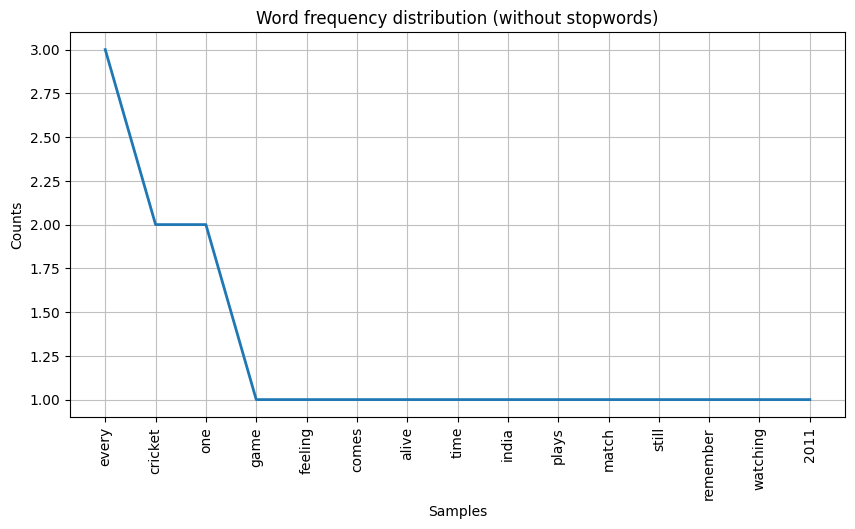

In [8]:
from nltk.probability import FreqDist
import matplotlib.pyplot as plt

fd = FreqDist(filtered_words)
print(fd.most_common(10))

plt.figure(figsize=(10, 5))
fd.plot(15, title="Word frequency distribution (without stopwords)")
plt.show()

## Q2. Stemming and Lemmatization (same paragraph as Q1)

**1. Extract only alphabetic words using re.findall()**

In [9]:
alpha_words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print(len(alpha_words))
print(alpha_words)

105
['cricket', 'is', 'more', 'than', 'just', 'a', 'game', 'for', 'me', 'it', 'is', 'a', 'feeling', 'that', 'comes', 'alive', 'every', 'time', 'india', 'plays', 'a', 'match', 'i', 'still', 'remember', 'watching', 'the', 'world', 'cup', 'final', 'with', 'my', 'family', 'and', 'shouting', 'at', 'the', 'television', 'after', 'every', 'ball', 'virat', 'kohli', 's', 'chase', 'against', 'pakistan', 'in', 'is', 'one', 'of', 'the', 'best', 'innings', 'i', 'have', 'ever', 'seen', 'playing', 'gully', 'cricket', 'with', 'friends', 'on', 'weekends', 'is', 'also', 'my', 'favourite', 'way', 'to', 'relax', 'after', 'a', 'tiring', 'week', 'every', 'player', 'on', 'the', 'field', 'teaches', 'us', 'something', 'about', 'hard', 'work', 'patience', 'and', 'never', 'giving', 'up', 'i', 'hope', 'to', 'watch', 'many', 'more', 'thrilling', 'matches', 'in', 'the', 'stadium', 'one', 'day']


**2. Remove stopwords**

In [10]:
alpha_filtered = [w for w in alpha_words if w not in stop_words]
print(len(alpha_filtered))
print(alpha_filtered)

60
['cricket', 'game', 'feeling', 'comes', 'alive', 'every', 'time', 'india', 'plays', 'match', 'still', 'remember', 'watching', 'world', 'cup', 'final', 'family', 'shouting', 'television', 'every', 'ball', 'virat', 'kohli', 'chase', 'pakistan', 'one', 'best', 'innings', 'ever', 'seen', 'playing', 'gully', 'cricket', 'friends', 'weekends', 'also', 'favourite', 'way', 'relax', 'tiring', 'week', 'every', 'player', 'field', 'teaches', 'us', 'something', 'hard', 'work', 'patience', 'never', 'giving', 'hope', 'watch', 'many', 'thrilling', 'matches', 'stadium', 'one', 'day']


**3. Stemming with PorterStemmer**

In [11]:
from nltk.stem import PorterStemmer

ps = PorterStemmer()
stemmed = [ps.stem(w) for w in alpha_filtered]
print(stemmed)

['cricket', 'game', 'feel', 'come', 'aliv', 'everi', 'time', 'india', 'play', 'match', 'still', 'rememb', 'watch', 'world', 'cup', 'final', 'famili', 'shout', 'televis', 'everi', 'ball', 'virat', 'kohli', 'chase', 'pakistan', 'one', 'best', 'inning', 'ever', 'seen', 'play', 'gulli', 'cricket', 'friend', 'weekend', 'also', 'favourit', 'way', 'relax', 'tire', 'week', 'everi', 'player', 'field', 'teach', 'us', 'someth', 'hard', 'work', 'patienc', 'never', 'give', 'hope', 'watch', 'mani', 'thrill', 'match', 'stadium', 'one', 'day']


**4. Lemmatization with WordNetLemmatizer**

In [12]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()
# default pos is noun, so i am also doing it with pos='v' to catch verbs
lemmatized = [lemmatizer.lemmatize(w) for w in alpha_filtered]
lemmatized_v = [lemmatizer.lemmatize(w, pos='v') for w in alpha_filtered]

print("Noun lemmas:", lemmatized)
print()
print("Verb lemmas:", lemmatized_v)

Noun lemmas: ['cricket', 'game', 'feeling', 'come', 'alive', 'every', 'time', 'india', 'play', 'match', 'still', 'remember', 'watching', 'world', 'cup', 'final', 'family', 'shouting', 'television', 'every', 'ball', 'virat', 'kohli', 'chase', 'pakistan', 'one', 'best', 'inning', 'ever', 'seen', 'playing', 'gully', 'cricket', 'friend', 'weekend', 'also', 'favourite', 'way', 'relax', 'tiring', 'week', 'every', 'player', 'field', 'teach', 'u', 'something', 'hard', 'work', 'patience', 'never', 'giving', 'hope', 'watch', 'many', 'thrilling', 'match', 'stadium', 'one', 'day']

Verb lemmas: ['cricket', 'game', 'feel', 'come', 'alive', 'every', 'time', 'india', 'play', 'match', 'still', 'remember', 'watch', 'world', 'cup', 'final', 'family', 'shout', 'television', 'every', 'ball', 'virat', 'kohli', 'chase', 'pakistan', 'one', 'best', 'innings', 'ever', 'see', 'play', 'gully', 'cricket', 'friends', 'weekend', 'also', 'favourite', 'way', 'relax', 'tire', 'week', 'every', 'player', 'field', 'teach

**5. Comparison**

In [13]:
import pandas as pd

df = pd.DataFrame({
    'original': alpha_filtered,
    'stemmed': stemmed,
    'lemma (noun)': lemmatized,
    'lemma (verb)': lemmatized_v
})
# showing only the rows where something changed
print(df[(df['original'] != df['stemmed']) | (df['original'] != df['lemma (verb)'])].to_string(index=False))

  original  stemmed lemma (noun) lemma (verb)
   feeling     feel      feeling         feel
     comes     come         come         come
     alive     aliv        alive        alive
     every    everi        every        every
     plays     play         play         play
  remember   rememb     remember     remember
  watching    watch     watching        watch
    family   famili       family       family
  shouting    shout     shouting        shout
television  televis   television   television
     every    everi        every        every
   innings   inning       inning      innings
      seen     seen         seen          see
   playing     play      playing         play
     gully    gulli        gully        gully
   friends   friend       friend      friends
  weekends  weekend      weekend      weekend
 favourite favourit    favourite    favourite
    tiring     tire       tiring         tire
     every    everi        every        every
   teaches    teach        teach  

**Observation:** The stemmer simply chops the endings off using rules, so it sometimes produces words that are not real words (for example `aliv`, `everi`, `famili`, `patienc`, `mani`). The lemmatizer uses the WordNet dictionary and always returns a proper word, but it needs the correct part of speech. With the default noun setting it leaves verbs like `watching`, `shouting` and `playing` unchanged, and only when I pass pos='v' it converts them to `watch`, `shout` and `play`. It also turned `us` into `u` which is a small mistake of the lemmatizer.

**When to prefer which:**
- Stemming is faster and simpler, so it is better for search engines, information retrieval and large datasets where speed matters and the output word does not have to be readable.
- Lemmatization is slower but gives meaningful words, so it is better for tasks like chatbots, sentiment analysis or text generation where the actual meaning of the word matters.

## Q3. Bag of Words and TF-IDF

In [14]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 3 short texts - news headline style, a product review and a sports line
texts = [
    "ISRO successfully launches a new weather satellite from Sriharikota and the launch was praised by scientists across the world",
    "The new phone has an amazing camera and the battery lasts all day but the charger is slow and the price is too high",
    "India beat Australia in a thrilling cricket match as the batsmen scored runs fast and the bowlers took wickets at the end"
]

for i, t in enumerate(texts, 1):
    print("Text", i, ":", t)

Text 1 : ISRO successfully launches a new weather satellite from Sriharikota and the launch was praised by scientists across the world
Text 2 : The new phone has an amazing camera and the battery lasts all day but the charger is slow and the price is too high
Text 3 : India beat Australia in a thrilling cricket match as the batsmen scored runs fast and the bowlers took wickets at the end


**1. Bag of Words using CountVectorizer**

In [15]:
cv = CountVectorizer(stop_words='english')
bow = cv.fit_transform(texts)

bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(), index=['Text 1', 'Text 2', 'Text 3'])
print("Vocabulary size:", len(cv.get_feature_names_out()))
bow_df

Vocabulary size: 35


,amazing,australia,batsmen,battery,beat,bowlers,camera,charger,cricket,day,...,scientists,scored,slow,sriharikota,successfully,thrilling,took,weather,wickets,world
Text 1,0,0,0,0,0,0,0,0,0,0,...,1,0,0,1,1,0,0,1,0,1
Text 2,1,0,0,1,0,0,1,1,0,1,...,0,0,1,0,0,0,0,0,0,0
Text 3,0,1,1,0,1,1,0,0,1,0,...,0,1,0,0,0,1,1,0,1,0


**2. TF-IDF using TfidfVectorizer**

In [16]:
tv = TfidfVectorizer(stop_words='english')
tfidf = tv.fit_transform(texts)

tfidf_df = pd.DataFrame(tfidf.toarray(), columns=tv.get_feature_names_out(), index=['Text 1', 'Text 2', 'Text 3'])
tfidf_df.round(3)

,amazing,australia,batsmen,battery,beat,bowlers,camera,charger,cricket,day,...,scientists,scored,slow,sriharikota,successfully,thrilling,took,weather,wickets,world
Text 1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.307,0.000,0.000,0.307,0.307,0.000,0.000,0.307,0.000,0.307
Text 2,0.307,0.000,0.000,0.307,0.000,0.000,0.307,0.307,0.000,0.307,...,0.000,0.000,0.307,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Text 3,0.000,0.267,0.267,0.000,0.267,0.267,0.000,0.000,0.267,0.000,...,0.000,0.267,0.000,0.000,0.000,0.267,0.267,0.000,0.267,0.000


**3. Top 3 keywords of each text**

In [17]:
features = tv.get_feature_names_out()

for i in range(len(texts)):
    row = tfidf[i].toarray()[0]
    top3 = row.argsort()[::-1][:3]
    print("Text", i + 1)
    for idx in top3:
        print("   ", features[idx], "->", round(row[idx], 3))

Text 1
    world -> 0.307
    weather -> 0.307
    sriharikota -> 0.307
Text 2
    phone -> 0.307
    price -> 0.307
    slow -> 0.307
Text 3
    wickets -> 0.267
    thrilling -> 0.267
    took -> 0.267


**Interpretation:** In bag of words every word is just counted, so common words get the same weight as important ones. TF-IDF reduces the score of words that appear in many texts and increases the score of words that are special to one text. Here every text has its own topic (space, phone, cricket), so the top keywords are the words that belong only to that text, like `weather`, `sriharikota` and `world` for Text 1, `phone`, `price` and `slow` for Text 2 and `wickets`, `thrilling` and `took` for Text 3. Many words have the same score because each of them appears only once in its text, so the order among them is decided by the vectorizer and not by importance. Words that appear in more than one text (like `new`) get a lower score.

## Q4. Text similarity (Jaccard and Cosine)

In [18]:
tech1 = """Artificial intelligence is the technology that allows machines to learn from data and make decisions.
It is used in healthcare, self driving cars and voice assistants.
Machine learning models are trained on large datasets to find patterns.
AI systems can improve with more data and are changing the way people work."""

tech2 = """Blockchain is a technology that stores data in blocks linked together in a secure chain.
It is used in cryptocurrency, banking and supply chain tracking.
There is no central authority, so every transaction is verified by many computers in the network.
Once data is stored on a blockchain it is very hard to change or hack."""

print(tech1)
print()
print(tech2)

Artificial intelligence is the technology that allows machines to learn from data and make decisions.
It is used in healthcare, self driving cars and voice assistants.
Machine learning models are trained on large datasets to find patterns.
AI systems can improve with more data and are changing the way people work.

Blockchain is a technology that stores data in blocks linked together in a secure chain.
It is used in cryptocurrency, banking and supply chain tracking.
There is no central authority, so every transaction is verified by many computers in the network.
Once data is stored on a blockchain it is very hard to change or hack.


**1. Preprocess and tokenize both texts**

In [19]:
def preprocess(t):
    t = t.lower()
    t = re.sub(r'[^\w\s]', '', t)
    tokens = word_tokenize(t)
    tokens = [w for w in tokens if w not in stop_words]
    return tokens

tokens1 = preprocess(tech1)
tokens2 = preprocess(tech2)

print(tokens1)
print()
print(tokens2)

['artificial', 'intelligence', 'technology', 'allows', 'machines', 'learn', 'data', 'make', 'decisions', 'used', 'healthcare', 'self', 'driving', 'cars', 'voice', 'assistants', 'machine', 'learning', 'models', 'trained', 'large', 'datasets', 'find', 'patterns', 'ai', 'systems', 'improve', 'data', 'changing', 'way', 'people', 'work']

['blockchain', 'technology', 'stores', 'data', 'blocks', 'linked', 'together', 'secure', 'chain', 'used', 'cryptocurrency', 'banking', 'supply', 'chain', 'tracking', 'central', 'authority', 'every', 'transaction', 'verified', 'many', 'computers', 'network', 'data', 'stored', 'blockchain', 'hard', 'change', 'hack']


**2a. Jaccard similarity using sets**

In [20]:
set1 = set(tokens1)
set2 = set(tokens2)

intersection = set1 & set2
union = set1 | set2

jaccard = len(intersection) / len(union)
print("Common words:", intersection)
print("Intersection:", len(intersection), " Union:", len(union))
print("Jaccard similarity:", round(jaccard, 4))

Common words: {'data', 'technology', 'used'}
Intersection: 3  Union: 54
Jaccard similarity: 0.0556


**2b. Cosine similarity using TfidfVectorizer + cosine_similarity()**

In [21]:
from sklearn.metrics.pairwise import cosine_similarity

clean1 = " ".join(tokens1)
clean2 = " ".join(tokens2)

vec = TfidfVectorizer()
mat = vec.fit_transform([clean1, clean2])

cos = cosine_similarity(mat[0], mat[1])[0][0]
print("Cosine similarity:", round(cos, 4))

Cosine similarity: 0.0963


**2c. Which metric is better here?**

In [22]:
print("Jaccard similarity:", round(jaccard, 4))
print("Cosine similarity :", round(cos, 4))

Jaccard similarity: 0.0556
Cosine similarity : 0.0963


**Analysis:** Both values come out low, which makes sense because AI and Blockchain are two different technologies and only share a few words like `data`, `technology` and `used`. 

Jaccard only checks whether a word is present or not, it ignores how many times a word is repeated and does not care which words are important. Cosine similarity with TF-IDF takes the frequency and importance of words into account, so a common word that appears in both texts does not boost the score much. In my case cosine similarity gives the better insight because it is weighted, while Jaccard is good only for a quick overlap check on short texts or sets of keywords.

## Q5. Sentiment analysis

In [23]:
from textblob import TextBlob

reviews = [
    "The headphones are amazing, the sound quality is excellent and the battery lasts really long.",
    "Very bad experience, the delivery was late and the product stopped working in two days.",
    "The phone arrived on Tuesday and it came with a charger and a case.",
    "I love this laptop, it is fast, light and the display is beautiful. Totally worth the money.",
    "Worst customer service ever, nobody replied to my complaint and I felt cheated.",
    "The food was delicious and the staff was very friendly, great place for family dinner.",
    "I bought this table last month and it is placed in the living room.",
    "Terrible quality, the colour faded after one wash and the stitching came out.",
    "Superb app, very easy to use and the new update made it even better.",
    "The book is average, some chapters are good but the ending is disappointing."
]

print(len(reviews), "reviews")

10 reviews


**1. Polarity and subjectivity (TextBlob)**

In [24]:
polarity = []
subjectivity = []
for r in reviews:
    s = TextBlob(r).sentiment
    polarity.append(s.polarity)
    subjectivity.append(s.subjectivity)

result = pd.DataFrame({'review': reviews, 'polarity': polarity, 'subjectivity': subjectivity})
result[['polarity', 'subjectivity']] = result[['polarity', 'subjectivity']].round(3)
pd.set_option('display.max_colwidth', 70)
result

,review,polarity,subjectivity
0,"The headphones are amazing, the sound quality is excellent and the...",0.488,0.675
1,"Very bad experience, the delivery was late and the product stopped...",-0.605,0.733
2,The phone arrived on Tuesday and it came with a charger and a case.,0.000,0.000
3,"I love this laptop, it is fast, light and the display is beautiful...",0.450,0.600
4,"Worst customer service ever, nobody replied to my complaint and I ...",-0.650,0.600
5,"The food was delicious and the staff was very friendly, great plac...",0.763,0.800
6,I bought this table last month and it is placed in the living room.,0.000,0.067
7,"Terrible quality, the colour faded after one wash and the stitchin...",-1.000,1.000
8,"Superb app, very easy to use and the new update made it even better.",0.550,0.739
9,"The book is average, some chapters are good but the ending is disa...",-0.017,0.567


**2. Classify into Positive / Negative / Neutral**

In [25]:
# polarity > 0.1 positive, < -0.1 negative, otherwise neutral
def classify(p):
    if p > 0.1:
        return 'Positive'
    elif p < -0.1:
        return 'Negative'
    else:
        return 'Neutral'

result['sentiment'] = result['polarity'].apply(classify)
print(result[['review', 'polarity', 'sentiment']].to_string(index=False))
print()
print(result['sentiment'].value_counts())

                                                                                       review  polarity sentiment
The headphones are amazing, the sound quality is excellent and the battery lasts really long.     0.488  Positive
      Very bad experience, the delivery was late and the product stopped working in two days.    -0.605  Negative
                          The phone arrived on Tuesday and it came with a charger and a case.     0.000   Neutral
 I love this laptop, it is fast, light and the display is beautiful. Totally worth the money.     0.450  Positive
              Worst customer service ever, nobody replied to my complaint and I felt cheated.    -0.650  Negative
       The food was delicious and the staff was very friendly, great place for family dinner.     0.763  Positive
                          I bought this table last month and it is placed in the living room.     0.000   Neutral
                Terrible quality, the colour faded after one wash and the stitching came

**3. Word cloud of positive reviews**

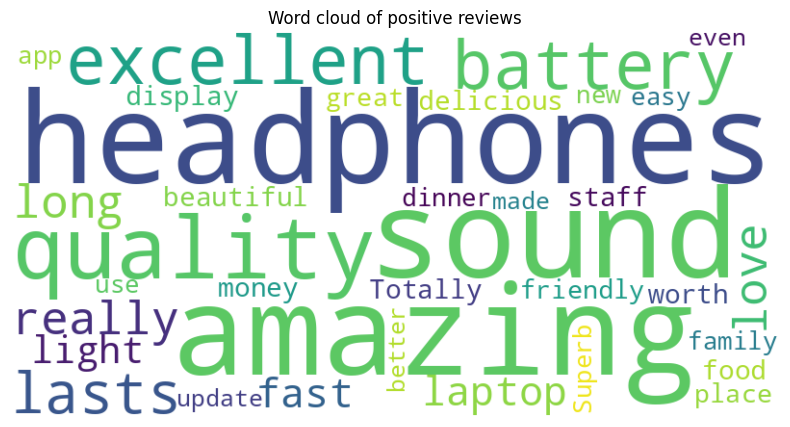

In [26]:
from wordcloud import WordCloud

positive_text = " ".join(result[result['sentiment'] == 'Positive']['review'])

wc = WordCloud(width=800, height=400, background_color='white', stopwords=set(stopwords.words('english'))).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word cloud of positive reviews")
plt.show()

## Q6. Text generation using LSTM

In [27]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# training paragraph (around 100 words)
data = """Cricket is a game loved by millions of people in India. Children play it in the streets and in the parks every evening. The game teaches us to work as a team and to never give up. A good batsman needs patience and a good bowler needs focus. When India wins a big match the whole country celebrates together. People gather around the television and cheer for every run and every wicket. The players practice for many hours to become better every day. Cricket brings people together and makes them happy. Every fan dreams of seeing his favourite team lift the trophy one day."""

print(len(data.split()), "words")

104 words


**1. Tokenize using Tokenizer()**

In [28]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts([data.lower()])
total_words = len(tokenizer.word_index) + 1

print("Total unique words:", total_words - 1)
print(list(tokenizer.word_index.items())[:15])

Total unique words: 69
[('the', 1), ('and', 2), ('a', 3), ('every', 4), ('people', 5), ('in', 6), ('to', 7), ('cricket', 8), ('game', 9), ('of', 10), ('india', 11), ('team', 12), ('good', 13), ('needs', 14), ('together', 15)]


**2. Create input sequences and build the model**

In [29]:
# making n-gram sequences line by line (each sentence)
input_sequences = []
for line in data.lower().split('.'):
    if line.strip() == '':
        continue
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i + 1])

max_len = max(len(s) for s in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_len, padding='pre')

# last word is the label, rest are the inputs
X = input_sequences[:, :-1]
y = input_sequences[:, -1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

print("Total sequences:", len(input_sequences))
print("X shape:", X.shape, " y shape:", y.shape)

Total sequences: 95
X shape: (95, 13)  y shape: (95, 70)


In [30]:
model = Sequential()
model.add(Embedding(total_words, 50, input_length=max_len - 1))
model.add(LSTM(100))
model.add(Dense(total_words, activation='softmax'))

model.build(input_shape=(None, max_len - 1))
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 13, 50)         │         3,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100)            │        60,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 70)             │         7,070 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 70,970 (277.23 KB)

 Trainable params: 70,970 (277.23 KB)

 Non-trainable params: 0 (0.00 B)

**3. Train the model and generate text**

Final accuracy: 0.9789
Final loss    : 0.2422


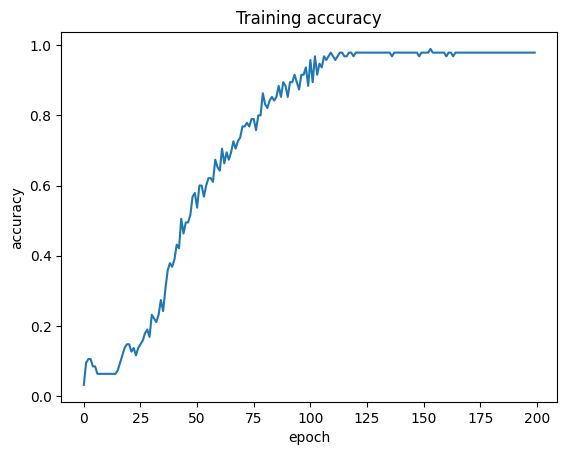

In [31]:
history = model.fit(X, y, epochs=200, verbose=0)
print("Final accuracy:", round(history.history['accuracy'][-1], 4))
print("Final loss    :", round(history.history['loss'][-1], 4))

plt.plot(history.history['accuracy'])
plt.title("Training accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.show()

In [32]:
def generate_text(seed_text, next_words=8):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_len - 1, padding='pre')
        predicted = np.argmax(model.predict(token_list, verbose=0), axis=-1)[0]
        for word, index in tokenizer.word_index.items():
            if index == predicted:
                seed_text += " " + word
                break
    return seed_text

print(generate_text("cricket", 8))
print(generate_text("the game", 8))
print(generate_text("every", 8))

cricket brings people together and makes them happy happy


the game teaches us to work as a team and


every fan dreams of seeing his favourite team lift


**Note:** The paragraph is very small, so the model mostly learns the sentences it has seen and the generated lines look similar to the training text. With a bigger dataset it would generate more new lines.